In [2]:
# importing needed packages
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy import stats
# import cartopy.crs as ccrs
# import cartopy.feature as cfeature
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [3]:
# read in the cleaned CSV with data from central valley stations
path = 'D:/Central Valley Fog/cleaned_data_Oct3.csv'
if os.path.exists(path):
    CV_rows = pd.read_csv(path, low_memory = False)
else:
    path = '/Volumes/disk1/Central Valley Fog/cleaned_data_Oct3.csv'
    CV_rows = pd.read_csv(path, low_memory = False)

print(CV_rows)

          STATION_ID         STATION                 DATE  year  month  day  \
0        USW00023155  BAKERSFIELD AP  1928-01-01 02:00:00  1928      1    1   
1        USW00023155  BAKERSFIELD AP  1928-01-01 05:00:00  1928      1    1   
2        USW00023155  BAKERSFIELD AP  1928-01-01 08:00:00  1928      1    1   
3        USW00023155  BAKERSFIELD AP  1928-01-01 09:00:00  1928      1    1   
4        USW00023155  BAKERSFIELD AP  1928-01-01 11:00:00  1928      1    1   
...              ...             ...                  ...   ...    ...  ...   
9293072  USW00023202  TRAVIS FLD AFB  2026-09-28 02:55:00  2026      9   28   
9293073  USW00023202  TRAVIS FLD AFB  2026-09-28 03:55:00  2026      9   28   
9293074  USW00023202  TRAVIS FLD AFB  2026-09-28 04:55:00  2026      9   28   
9293075  USW00023202  TRAVIS FLD AFB  2026-09-28 05:55:00  2026      9   28   
9293076  USW00023202  TRAVIS FLD AFB  2026-09-28 06:55:00  2026      9   28   

         hour  minute  LATITUDE  LONGITUDE  HourlyD

In [4]:
#Remove duplicate hours for each station
CV_rows = CV_rows.drop_duplicates(subset=['STATION', 'year', 'month', 'day', 'hour'])

print(CV_rows.shape)

(7477658, 16)


In [5]:
# Exclude days from April through October (months 4-10) in CV_rows
CV_rows = CV_rows[~CV_rows['month'].isin([4, 5, 6, 7, 8, 9, 10])]

print("CV_rows after removing April-October:", CV_rows.shape)

CV_rows after removing April-October: (3092926, 16)


In [6]:
# Exclude the year 2026
CV_rows = CV_rows[CV_rows['year'] != 2026]

print("CV_data after removing year 2026:", CV_rows.shape)

CV_data after removing year 2026: (3068714, 16)


In [7]:
# Find the earliest year with recorded data for each station
earliest_year_by_station = CV_rows.groupby("STATION")["year"].min().reset_index()
earliest_year_by_station.columns = ["STATION", "earliest_year"]
earliest_year_by_station = earliest_year_by_station.sort_values("earliest_year")

print("Earliest year with recorded data for each station:")
print(earliest_year_by_station)

Earliest year with recorded data for each station:
                     STATION  earliest_year
0             BAKERSFIELD AP           1928
7      SACRAMENTO MATHER AFB           1930
6         SACRAMENTO AP ASOS           1931
8   SACRAMENTO MCCLELLAN AFB           1939
10               STOCKTON AP           1941
3       FRESNO YOSEMITE INTL           1941
2                 CASTLE AFB           1942
11            TRAVIS FLD AFB           1943
5                 REDDING AP           1944
1                  BEALE AFB           1959
4         LEMOORE REEVES NAS           1961
9        SACRAMENTO METRO AP           1972


In [8]:
# Remove the earliest year for each station
CV_rows = CV_rows.merge(
    earliest_year_by_station,
    left_on="STATION",
    right_on="STATION",
    how="left"
)

CV_rows = CV_rows[CV_rows["year"] != CV_rows["earliest_year"]].drop(columns="earliest_year")

print("CV_rows after removing earliest year for each station:", CV_rows.shape)

CV_rows after removing earliest year for each station: (3050617, 16)


In [9]:
CV_rows['HourlyDewpointDepression'] = (
    CV_rows['HourlyDryBulbTemperature'] - CV_rows['HourlyDewPointTemperature']
)

CV_rows[['HourlyDryBulbTemperature', 'HourlyDewPointTemperature', 'HourlyDewpointDepression']].head()

,HourlyDryBulbTemperature,HourlyDewPointTemperature,HourlyDewpointDepression
462,NaN,NaN,NaN
463,-3.3,NaN,NaN
464,-6.1,NaN,NaN
465,-5.6,NaN,NaN
466,-2.2,NaN,NaN


In [10]:
# Classify each observation as up-valley or down-valley relative to valley angle = 330°
valley_angle = 330.0  # interpreted as the up-valley flow direction (toward 330°)

wd = pd.to_numeric(CV_rows["HourlyWindDirection"], errors="coerce")  # meteorological "from" direction
ws = pd.to_numeric(CV_rows["HourlyWindSpeed"], errors="coerce")

# Convert to "to" direction (direction wind is blowing toward)
wd_to = (wd + 180.0) % 360.0

# Signed alignment with valley axis (+ up-valley, - down-valley)
# cos(delta) > 0 means aligned with up-valley axis, < 0 means opposite (down-valley)
delta = np.deg2rad(wd_to - valley_angle)
valley_alignment = np.cos(delta)

# Optional speed-weighted along-valley component
CV_rows["valley_along_component"] = valley_alignment * ws

calm_mask = wd.eq(0) | ws.eq(0)  # "000" direction and/or zero speed => calm
missing_mask = wd.isna() | ws.isna()

# Classify each observation as "up_valley", "down_valley", "cross_valley", "calm", or "missing"
CV_rows["valley_wind_type"] = np.select(
    [
        missing_mask,
        calm_mask,
        valley_alignment > 0,
        valley_alignment < 0,
    ],
    [
        "missing",
        "calm",
        "up_valley",
        "down_valley",
    ],
    default="cross_valley",
)

# Quick station-level check of the counts of each valley wind type
station_valley_counts = (
    CV_rows.groupby(["STATION", "valley_wind_type"])
    .size()
    .unstack(fill_value=0)
)

station_valley_counts.head()

valley_wind_type,down_valley,missing,up_valley
STATION,,,
BAKERSFIELD AP,154068,66494,127455
BEALE AFB,73309,46374,99122
CASTLE AFB,74113,85096,68811
FRESNO YOSEMITE INTL,105807,59938,125760
LEMOORE REEVES NAS,102358,42053,72260


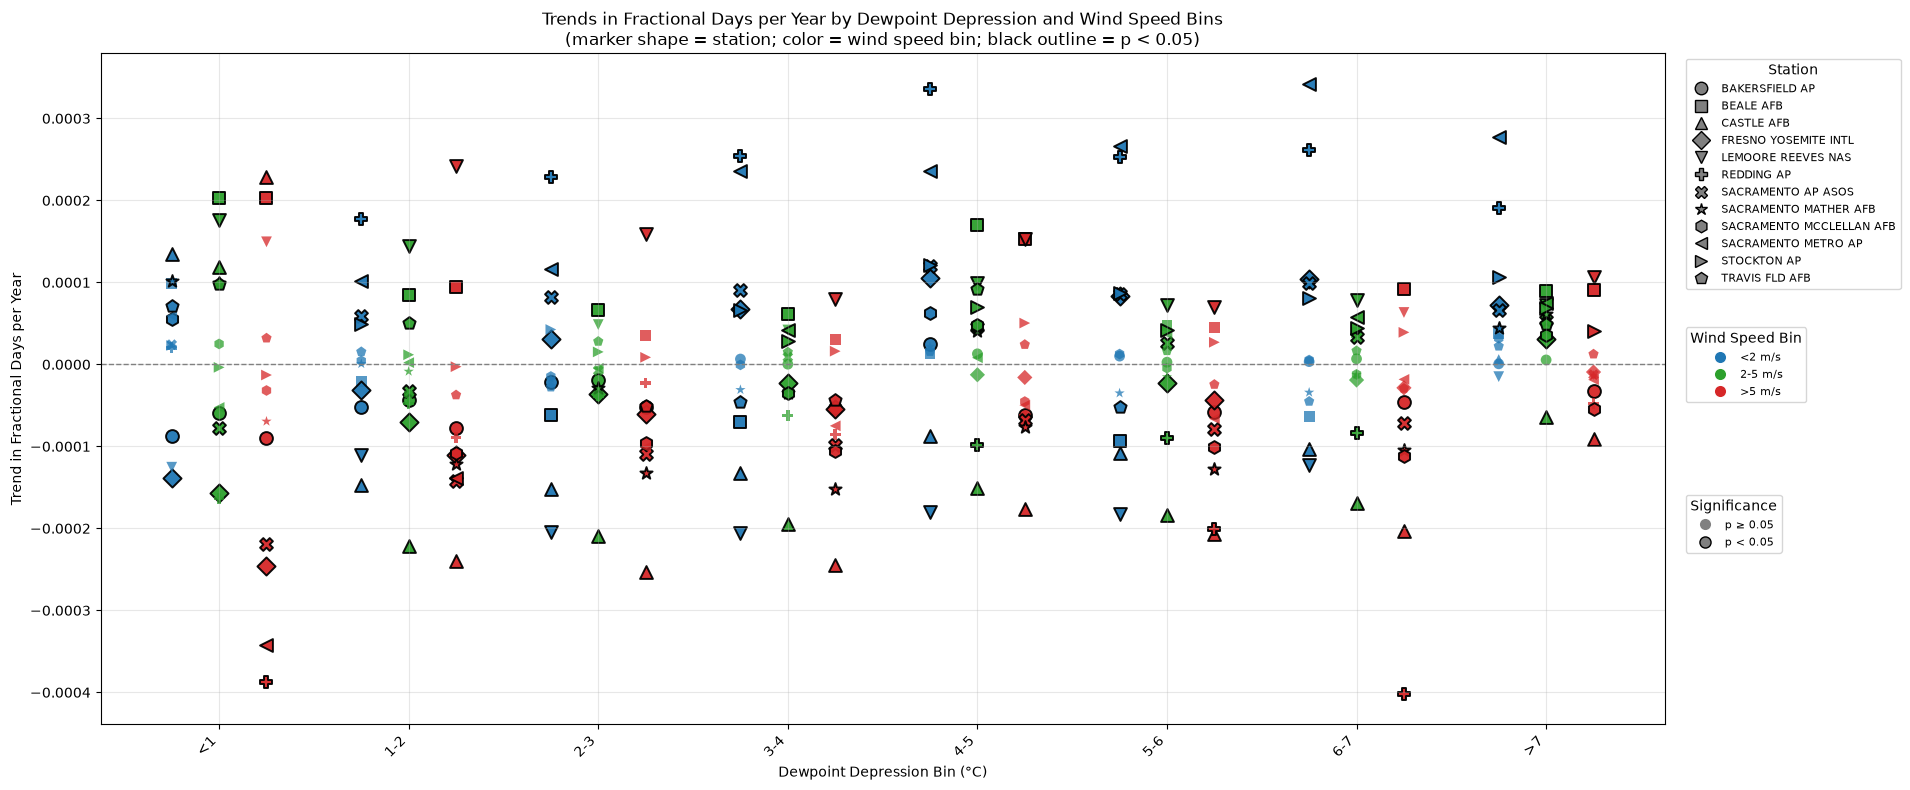

,STATION,dd_bin,wind_bin,slope_per_year,p_value,significant
4,BAKERSFIELD AP,1-2,2-5,-0.000043,0.002129,True
3,BAKERSFIELD AP,1-2,<2,-0.000051,0.000274,True
5,BAKERSFIELD AP,1-2,>5,-0.000077,0.000008,True
7,BAKERSFIELD AP,2-3,2-5,-0.000019,0.040146,True
6,BAKERSFIELD AP,2-3,<2,-0.000022,0.014090,True
...,...,...,...,...,...,...
264,TRAVIS FLD AFB,<1,<2,0.000071,0.029031,True
266,TRAVIS FLD AFB,<1,>5,0.000032,0.483834,False
286,TRAVIS FLD AFB,>7,2-5,0.000050,0.000206,True
285,TRAVIS FLD AFB,>7,<2,0.000022,0.219857,False


In [11]:
# Trend in fractional unique days per year (y-axis) by dewpoint depression bin
# (<0 to >7 in 0.5°C steps, x-axis), with marker shape = station and
# color = wind speed bin (<2, 2-5, >5 m/s). Black outline = p < 0.05.

station_names = CV_rows["STATION"].unique()

# Dewpoint depression bins: <1, 1-3, 3-5, 5-7, >7
inner_dd_edges = np.arange(1, 8, 1)
dd_bin_edges = np.concatenate(([-np.inf], inner_dd_edges, [np.inf]))
dd_bin_labels = (
    ["<1"]
    + [f"{inner_dd_edges[i]:g}-{inner_dd_edges[i + 1]:g}" for i in range(len(inner_dd_edges) - 1)]
    + [">7"]
)

# Wind speed bins
wind_bin_edges = [0.0, 2.0, 5.0, np.inf]
wind_bin_labels = ["<2", "2-5", ">5"]

plot_data = CV_rows.loc[
    CV_rows["HourlyDewpointDepression"].notna()
    & CV_rows["HourlyWindSpeed"].notna(),
    ["STATION", "year", "month", "day", "HourlyDewpointDepression", "HourlyWindSpeed"],
].copy()

plot_data["dd_bin"] = pd.cut(
    plot_data["HourlyDewpointDepression"],
    bins=dd_bin_edges, labels=dd_bin_labels, right=False,
)
plot_data["wind_bin"] = pd.cut(
    plot_data["HourlyWindSpeed"],
    bins=wind_bin_edges, labels=wind_bin_labels, right=False, include_lowest=True,
)

trend_records = []

for station in station_names:
    station_data = plot_data[plot_data["STATION"] == station]
    years = np.sort(station_data["year"].unique())

    if len(years) < 3:
        continue

    for dd_label in dd_bin_labels:
        for wind_label in wind_bin_labels:
            subset = station_data[
                (station_data["dd_bin"] == dd_label)
                & (station_data["wind_bin"] == wind_label)
            ]

            annual_days = (
                subset[["year", "month", "day"]]
                .drop_duplicates()
                .groupby("year")
                .size()
                .reindex(years, fill_value=0)
            )

            if annual_days.sum() == 0:
                continue

            y = (annual_days / annual_days.sum()).to_numpy()
            slope, intercept, r_value, p_value, std_err = stats.linregress(years, y)

            trend_records.append({
                "STATION": station,
                "dd_bin": dd_label,
                "wind_bin": wind_label,
                "slope_per_year": slope,
                "p_value": p_value,
                "significant": bool(np.isfinite(p_value) and p_value < 0.05),
            })

trend_df = pd.DataFrame(trend_records)

# Plot
fig, ax = plt.subplots(figsize=(18, 8))

dd_positions = {label: i for i, label in enumerate(dd_bin_labels)}
wind_colors = {"<2": "#1f77b4", "2-5": "#2ca02c", ">5": "#d62728"}
wind_offsets = dict(zip(wind_bin_labels, np.linspace(-0.25, 0.25, len(wind_bin_labels))))

marker_cycle = ["o", "s", "^", "D", "v", "P", "X", "*", "h", "<", ">", "p"]
station_markers = {st: marker_cycle[i % len(marker_cycle)] for i, st in enumerate(station_names)}

for station in station_names:
    sub = trend_df[trend_df["STATION"] == station]
    if sub.empty:
        continue

    marker = station_markers[station]

    for wind_label in wind_bin_labels:
        wind_sub = sub[sub["wind_bin"] == wind_label]
        if wind_sub.empty:
            continue

        x_vals = wind_sub["dd_bin"].map(dd_positions).to_numpy() + wind_offsets[wind_label]

        ns = ~wind_sub["significant"]
        ax.scatter(
            x_vals[ns], wind_sub.loc[ns, "slope_per_year"],
            s=60, marker=marker, color=wind_colors[wind_label],
            alpha=0.75, edgecolors="none",
        )

        sg = wind_sub["significant"]
        ax.scatter(
            x_vals[sg], wind_sub.loc[sg, "slope_per_year"],
            s=85, marker=marker, color=wind_colors[wind_label],
            alpha=0.95, edgecolors="black", linewidths=1.4,
        )

ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(range(len(dd_bin_labels)))
ax.set_xticklabels(dd_bin_labels, rotation=45, ha="right")
ax.set_xlabel("Dewpoint Depression Bin (°C)")
ax.set_ylabel("Trend in Fractional Days per Year")
ax.set_title(
    "Trends in Fractional Days per Year by Dewpoint Depression and Wind Speed Bins\n"
    "(marker shape = station; color = wind speed bin; black outline = p < 0.05)"
)
ax.grid(True, alpha=0.3)

station_handles = [
    plt.Line2D([0], [0], marker=station_markers[st], color="w", label=st,
               markerfacecolor="gray", markeredgecolor="black", markersize=9)
    for st in station_names
]
legend1 = ax.legend(handles=station_handles, title="Station",
                    loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
ax.add_artist(legend1)

wind_handles = [
    plt.Line2D([0], [0], marker="o", color="w", label=f"{wl} m/s",
               markerfacecolor=wind_colors[wl], markersize=9)
    for wl in wind_bin_labels
]
legend2 = ax.legend(handles=wind_handles, title="Wind Speed Bin",
                    loc="upper left", bbox_to_anchor=(1.01, 0.6), fontsize=8)
ax.add_artist(legend2)

sig_handles = [
    plt.Line2D([0], [0], marker="o", color="w", label="p ≥ 0.05",
               markerfacecolor="gray", markeredgecolor="none", markersize=8),
    plt.Line2D([0], [0], marker="o", color="w", label="p < 0.05",
               markerfacecolor="gray", markeredgecolor="black", markersize=8),
]
ax.legend(handles=sig_handles, title="Significance",
          loc="upper left", bbox_to_anchor=(1.01, 0.35), fontsize=8)

plt.tight_layout()
plt.show()

display(trend_df.sort_values(["STATION", "dd_bin", "wind_bin"]))

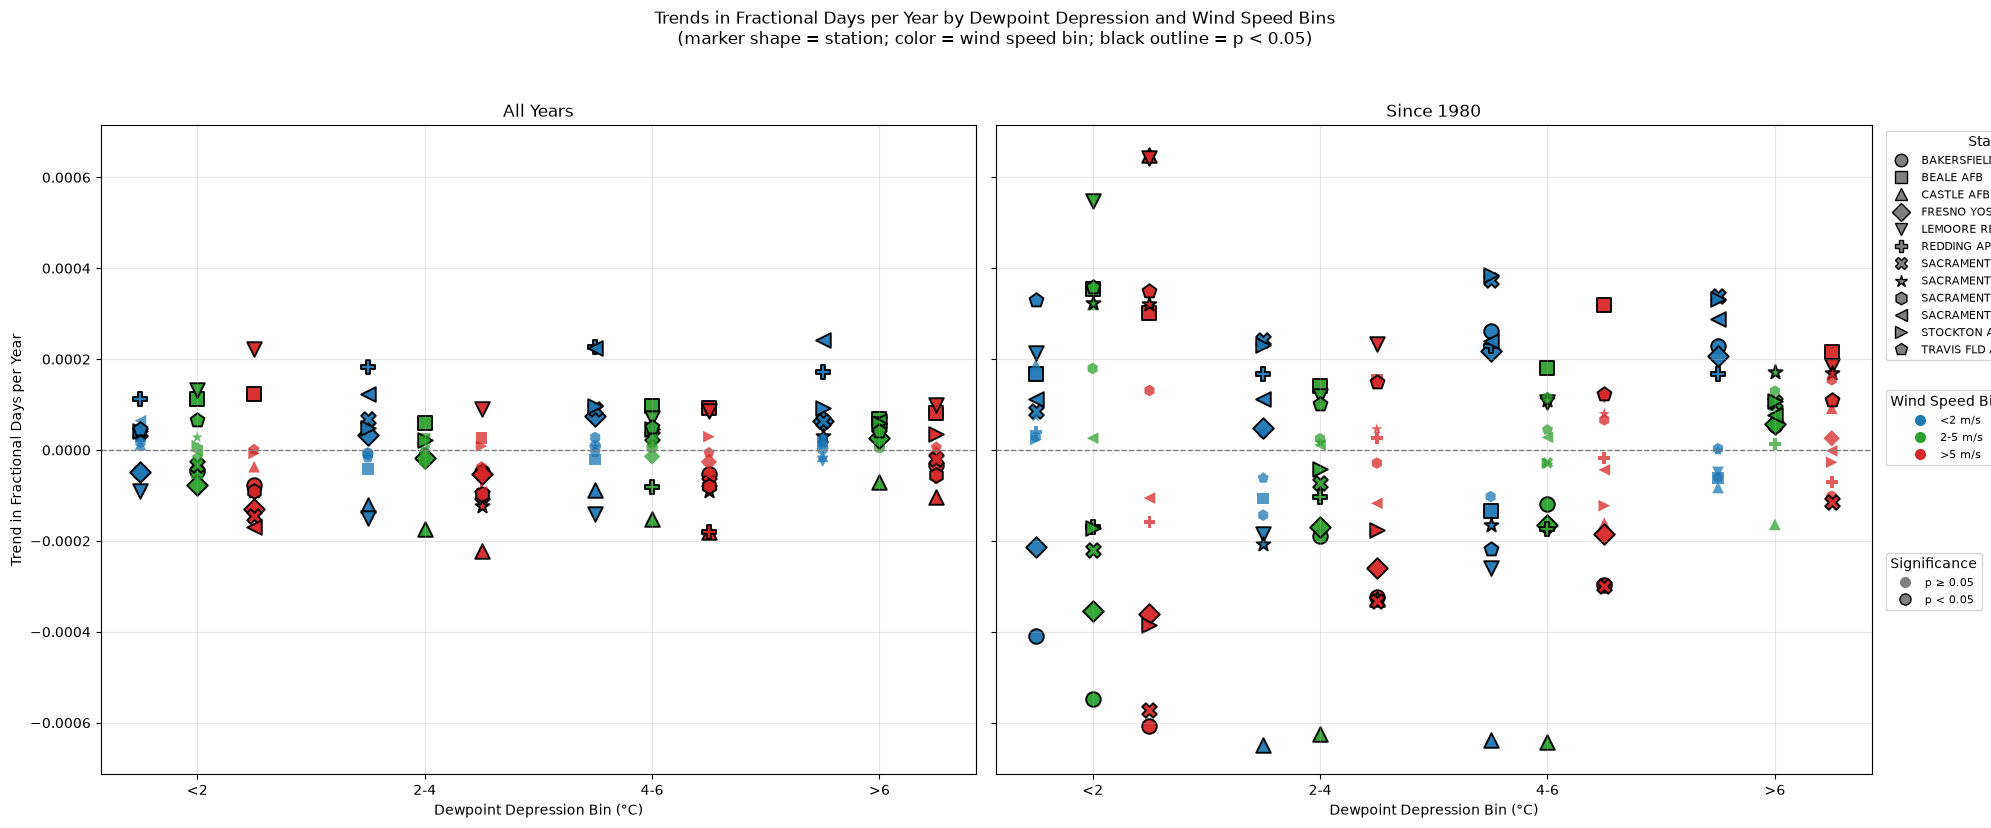

,period,STATION,dd_bin,wind_bin,slope_per_year,p_value,significant
0,All Years,BAKERSFIELD AP,<2,<2,-0.000048,0.000823,True
1,All Years,BAKERSFIELD AP,<2,2-5,-0.000047,0.000851,True
2,All Years,BAKERSFIELD AP,<2,>5,-0.000077,0.000040,True
3,All Years,BAKERSFIELD AP,2-4,<2,-0.000008,0.258787,False
4,All Years,BAKERSFIELD AP,2-4,2-5,-0.000007,0.249514,False
...,...,...,...,...,...,...,...
283,Since 1980,TRAVIS FLD AFB,4-6,2-5,0.000045,0.216489,False
284,Since 1980,TRAVIS FLD AFB,4-6,>5,0.000124,0.019475,True
285,Since 1980,TRAVIS FLD AFB,>6,<2,-0.000060,0.305857,False
286,Since 1980,TRAVIS FLD AFB,>6,2-5,0.000053,0.101145,False


In [12]:
# Trend in fractional unique days per year by dewpoint depression bin
# (<2, 2-4, 4-6, >6) and wind speed bin (<2, 2-5, >5 m/s), computed for
# all years and since 1980. Marker shape = station; color = wind bin;
# black outline = p < 0.05.

# New dewpoint depression bins
dd2_bin_edges = [-np.inf, 2.0, 4.0, 6.0, np.inf]
dd2_bin_labels = ["<2", "2-4", "4-6", ">6"]
dd2_positions = {label: i for i, label in enumerate(dd2_bin_labels)}

plot_data2 = CV_rows.loc[
    CV_rows["HourlyDewpointDepression"].notna()
    & CV_rows["HourlyWindSpeed"].notna(),
    ["STATION", "year", "month", "day", "HourlyDewpointDepression", "HourlyWindSpeed"],
].copy()

plot_data2["dd_bin"] = pd.cut(
    plot_data2["HourlyDewpointDepression"],
    bins=dd2_bin_edges, labels=dd2_bin_labels, right=False,
)
plot_data2["wind_bin"] = pd.cut(
    plot_data2["HourlyWindSpeed"],
    bins=wind_bin_edges, labels=wind_bin_labels, right=False, include_lowest=True,
)

periods = {"All Years": None, "Since 1980": 1980}

trend_records2 = []

for period_name, start_year in periods.items():
    period_data = plot_data2 if start_year is None else plot_data2[plot_data2["year"] >= start_year]

    for station in station_names:
        station_data = period_data[period_data["STATION"] == station]
        years = np.sort(station_data["year"].unique())

        if len(years) < 3:
            continue

        for dd_label in dd2_bin_labels:
            for wind_label in wind_bin_labels:
                subset = station_data[
                    (station_data["dd_bin"] == dd_label)
                    & (station_data["wind_bin"] == wind_label)
                ]

                annual_days = (
                    subset[["year", "month", "day"]]
                    .drop_duplicates()
                    .groupby("year")
                    .size()
                    .reindex(years, fill_value=0)
                )

                if annual_days.sum() == 0:
                    continue

                y = (annual_days / annual_days.sum()).to_numpy()
                slope, intercept, r_value, p_value, std_err = stats.linregress(years, y)

                trend_records2.append({
                    "period": period_name,
                    "STATION": station,
                    "dd_bin": dd_label,
                    "wind_bin": wind_label,
                    "slope_per_year": slope,
                    "p_value": p_value,
                    "significant": bool(np.isfinite(p_value) and p_value < 0.05),
                })

trend_df2 = pd.DataFrame(trend_records2)

# Keep logical ordering for display
trend_df2["period"] = pd.Categorical(trend_df2["period"], categories=list(periods), ordered=True)
trend_df2["dd_bin"] = pd.Categorical(trend_df2["dd_bin"], categories=dd2_bin_labels, ordered=True)
trend_df2["wind_bin"] = pd.Categorical(trend_df2["wind_bin"], categories=wind_bin_labels, ordered=True)

# Plot: one panel per period
fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharey=True)

for ax, period_name in zip(axes, periods):
    period_trends = trend_df2[trend_df2["period"] == period_name]

    for station in station_names:
        sub = period_trends[period_trends["STATION"] == station]
        if sub.empty:
            continue

        marker = station_markers[station]

        for wind_label in wind_bin_labels:
            wind_sub = sub[sub["wind_bin"] == wind_label]
            if wind_sub.empty:
                continue

            x_vals = wind_sub["dd_bin"].map(dd2_positions).to_numpy() + wind_offsets[wind_label]

            ns = ~wind_sub["significant"]
            ax.scatter(
                x_vals[ns], wind_sub.loc[ns, "slope_per_year"],
                s=70, marker=marker, color=wind_colors[wind_label],
                alpha=0.75, edgecolors="none",
            )

            sg = wind_sub["significant"]
            ax.scatter(
                x_vals[sg], wind_sub.loc[sg, "slope_per_year"],
                s=110, marker=marker, color=wind_colors[wind_label],
                alpha=0.95, edgecolors="black", linewidths=1.4,
            )

    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_xticks(range(len(dd2_bin_labels)))
    ax.set_xticklabels(dd2_bin_labels)
    ax.set_xlabel("Dewpoint Depression Bin (°C)")
    ax.set_title(period_name)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Trend in Fractional Days per Year")

fig.suptitle(
    "Trends in Fractional Days per Year by Dewpoint Depression and Wind Speed Bins\n"
    "(marker shape = station; color = wind speed bin; black outline = p < 0.05)",
    y=1.03,
)

station_handles = [
    plt.Line2D([0], [0], marker=station_markers[st], color="w", label=st,
               markerfacecolor="gray", markeredgecolor="black", markersize=9)
    for st in station_names
]
legend1 = axes[1].legend(handles=station_handles, title="Station",
                         loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
axes[1].add_artist(legend1)

wind_handles = [
    plt.Line2D([0], [0], marker="o", color="w", label=f"{wl} m/s",
               markerfacecolor=wind_colors[wl], markersize=9)
    for wl in wind_bin_labels
]
legend2 = axes[1].legend(handles=wind_handles, title="Wind Speed Bin",
                         loc="upper left", bbox_to_anchor=(1.01, 0.6), fontsize=8)
axes[1].add_artist(legend2)

sig_handles = [
    plt.Line2D([0], [0], marker="o", color="w", label="p ≥ 0.05",
               markerfacecolor="gray", markeredgecolor="none", markersize=8),
    plt.Line2D([0], [0], marker="o", color="w", label="p < 0.05",
               markerfacecolor="gray", markeredgecolor="black", markersize=8),
]
axes[1].legend(handles=sig_handles, title="Significance",
               loc="upper left", bbox_to_anchor=(1.01, 0.35), fontsize=8)

plt.tight_layout()
plt.show()

display(trend_df2.sort_values(["period", "STATION", "dd_bin", "wind_bin"]))

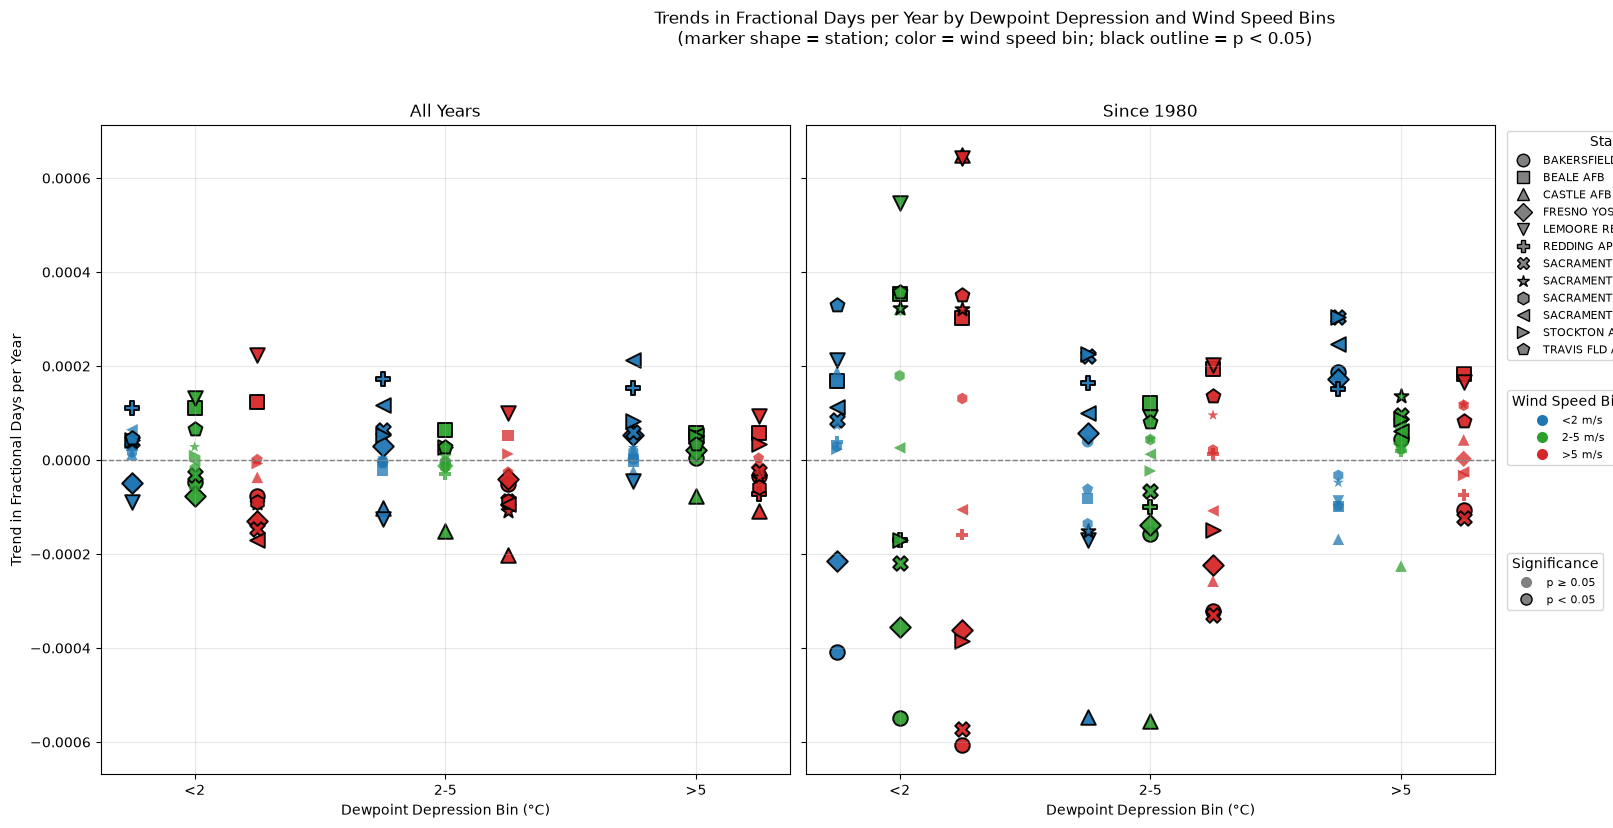

,period,STATION,dd_bin,wind_bin,slope_per_year,p_value,significant
0,All Years,BAKERSFIELD AP,<2,<2,-0.000048,0.000823,True
1,All Years,BAKERSFIELD AP,<2,2-5,-0.000047,0.000851,True
2,All Years,BAKERSFIELD AP,<2,>5,-0.000077,0.000040,True
3,All Years,BAKERSFIELD AP,2-5,<2,-0.000003,0.565070,False
4,All Years,BAKERSFIELD AP,2-5,2-5,-0.000004,0.417324,False
...,...,...,...,...,...,...,...
211,Since 1980,TRAVIS FLD AFB,2-5,2-5,0.000082,0.004920,True
212,Since 1980,TRAVIS FLD AFB,2-5,>5,0.000137,0.021254,True
213,Since 1980,TRAVIS FLD AFB,>5,<2,-0.000098,0.076620,False
214,Since 1980,TRAVIS FLD AFB,>5,2-5,0.000023,0.426170,False


In [17]:
# Trend in fractional unique days per year by dewpoint depression bin
# (<2, 2-5, >5) and wind speed bin (<2, 2-5, >5 m/s), computed for
# all years and since 1980. Marker shape = station; color = wind bin;
# black outline = p < 0.05.

dd25_bin_edges = [-np.inf, 2.0, 5.0, np.inf]
dd25_bin_labels = ["<2", "2-5", ">5"]
dd25_positions = {label: i for i, label in enumerate(dd25_bin_labels)}

plot_data25 = CV_rows.loc[
    CV_rows["HourlyDewpointDepression"].notna()
    & CV_rows["HourlyWindSpeed"].notna(),
    ["STATION", "year", "month", "day", "HourlyDewpointDepression", "HourlyWindSpeed"],
].copy()

plot_data25["dd_bin"] = pd.cut(
    plot_data25["HourlyDewpointDepression"],
    bins=dd25_bin_edges, labels=dd25_bin_labels, right=False,
)
plot_data25["wind_bin"] = pd.cut(
    plot_data25["HourlyWindSpeed"],
    bins=wind_bin_edges, labels=wind_bin_labels, right=False, include_lowest=True,
)

trend_records25 = []

for period_name, start_year in periods.items():
    period_data = plot_data25 if start_year is None else plot_data25[plot_data25["year"] >= start_year]

    for station in station_names:
        station_data = period_data[period_data["STATION"] == station]
        years = np.sort(station_data["year"].unique())

        if len(years) < 3:
            continue

        for dd_label in dd25_bin_labels:
            for wind_label in wind_bin_labels:
                subset = station_data[
                    (station_data["dd_bin"] == dd_label)
                    & (station_data["wind_bin"] == wind_label)
                ]

                annual_days = (
                    subset[["year", "month", "day"]]
                    .drop_duplicates()
                    .groupby("year")
                    .size()
                    .reindex(years, fill_value=0)
                )

                if annual_days.sum() == 0:
                    continue

                y = (annual_days / annual_days.sum()).to_numpy()
                slope, intercept, r_value, p_value, std_err = stats.linregress(years, y)

                trend_records25.append({
                    "period": period_name,
                    "STATION": station,
                    "dd_bin": dd_label,
                    "wind_bin": wind_label,
                    "slope_per_year": slope,
                    "p_value": p_value,
                    "significant": bool(np.isfinite(p_value) and p_value < 0.05),
                })

trend_df25 = pd.DataFrame(trend_records25)

# Keep logical ordering for display
trend_df25["period"] = pd.Categorical(trend_df25["period"], categories=list(periods), ordered=True)
trend_df25["dd_bin"] = pd.Categorical(trend_df25["dd_bin"], categories=dd25_bin_labels, ordered=True)
trend_df25["wind_bin"] = pd.Categorical(trend_df25["wind_bin"], categories=wind_bin_labels, ordered=True)

# Plot: one panel per period
fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharey=True)

for ax, period_name in zip(axes, periods):
    period_trends = trend_df25[trend_df25["period"] == period_name]

    for station in station_names:
        sub = period_trends[period_trends["STATION"] == station]
        if sub.empty:
            continue

        marker = station_markers[station]

        for wind_label in wind_bin_labels:
            wind_sub = sub[sub["wind_bin"] == wind_label]
            if wind_sub.empty:
                continue

            x_vals = wind_sub["dd_bin"].map(dd25_positions).to_numpy() + wind_offsets[wind_label]

            ns = ~wind_sub["significant"]
            ax.scatter(
                x_vals[ns], wind_sub.loc[ns, "slope_per_year"],
                s=70, marker=marker, color=wind_colors[wind_label],
                alpha=0.75, edgecolors="none",
            )

            sg = wind_sub["significant"]
            ax.scatter(
                x_vals[sg], wind_sub.loc[sg, "slope_per_year"],
                s=110, marker=marker, color=wind_colors[wind_label],
                alpha=0.95, edgecolors="black", linewidths=1.4,
            )

    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_xticks(range(len(dd25_bin_labels)))
    ax.set_xticklabels(dd25_bin_labels)
    ax.set_xlabel("Dewpoint Depression Bin (°C)")
    ax.set_title(period_name)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Trend in Fractional Days per Year")

fig.suptitle(
    "Trends in Fractional Days per Year by Dewpoint Depression and Wind Speed Bins\n"
    "(marker shape = station; color = wind speed bin; black outline = p < 0.05)",
    y=1.03,
)

station_handles = [
    plt.Line2D([0], [0], marker=station_markers[st], color="w", label=st,
               markerfacecolor="gray", markeredgecolor="black", markersize=9)
    for st in station_names
]
legend1 = axes[1].legend(handles=station_handles, title="Station",
                         loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
axes[1].add_artist(legend1)

wind_handles = [
    plt.Line2D([0], [0], marker="o", color="w", label=f"{wl} m/s",
               markerfacecolor=wind_colors[wl], markersize=9)
    for wl in wind_bin_labels
]
legend2 = axes[1].legend(handles=wind_handles, title="Wind Speed Bin",
                         loc="upper left", bbox_to_anchor=(1.01, 0.6), fontsize=8)
axes[1].add_artist(legend2)

sig_handles = [
    plt.Line2D([0], [0], marker="o", color="w", label="p ≥ 0.05",
               markerfacecolor="gray", markeredgecolor="none", markersize=8),
    plt.Line2D([0], [0], marker="o", color="w", label="p < 0.05",
               markerfacecolor="gray", markeredgecolor="black", markersize=8),
]
axes[1].legend(handles=sig_handles, title="Significance",
               loc="upper left", bbox_to_anchor=(1.01, 0.35), fontsize=8)

plt.tight_layout()
plt.subplots_adjust(right=0.75)
plt.show()

display(trend_df25.sort_values(["period", "STATION", "dd_bin", "wind_bin"]))

Station BAKERSFIELD AP uses marker 'o'
Station BEALE AFB uses marker 's'
Station CASTLE AFB uses marker '^'
Station FRESNO YOSEMITE INTL uses marker 'D'
Station LEMOORE REEVES NAS uses marker 'v'
Station REDDING AP uses marker 'P'
Station SACRAMENTO AP ASOS uses marker 'X'
Station SACRAMENTO MATHER AFB uses marker '*'
Station SACRAMENTO MCCLELLAN AFB uses marker 'h'
Station SACRAMENTO METRO AP uses marker '<'
Station STOCKTON AP uses marker '>'
Station TRAVIS FLD AFB uses marker 'p'


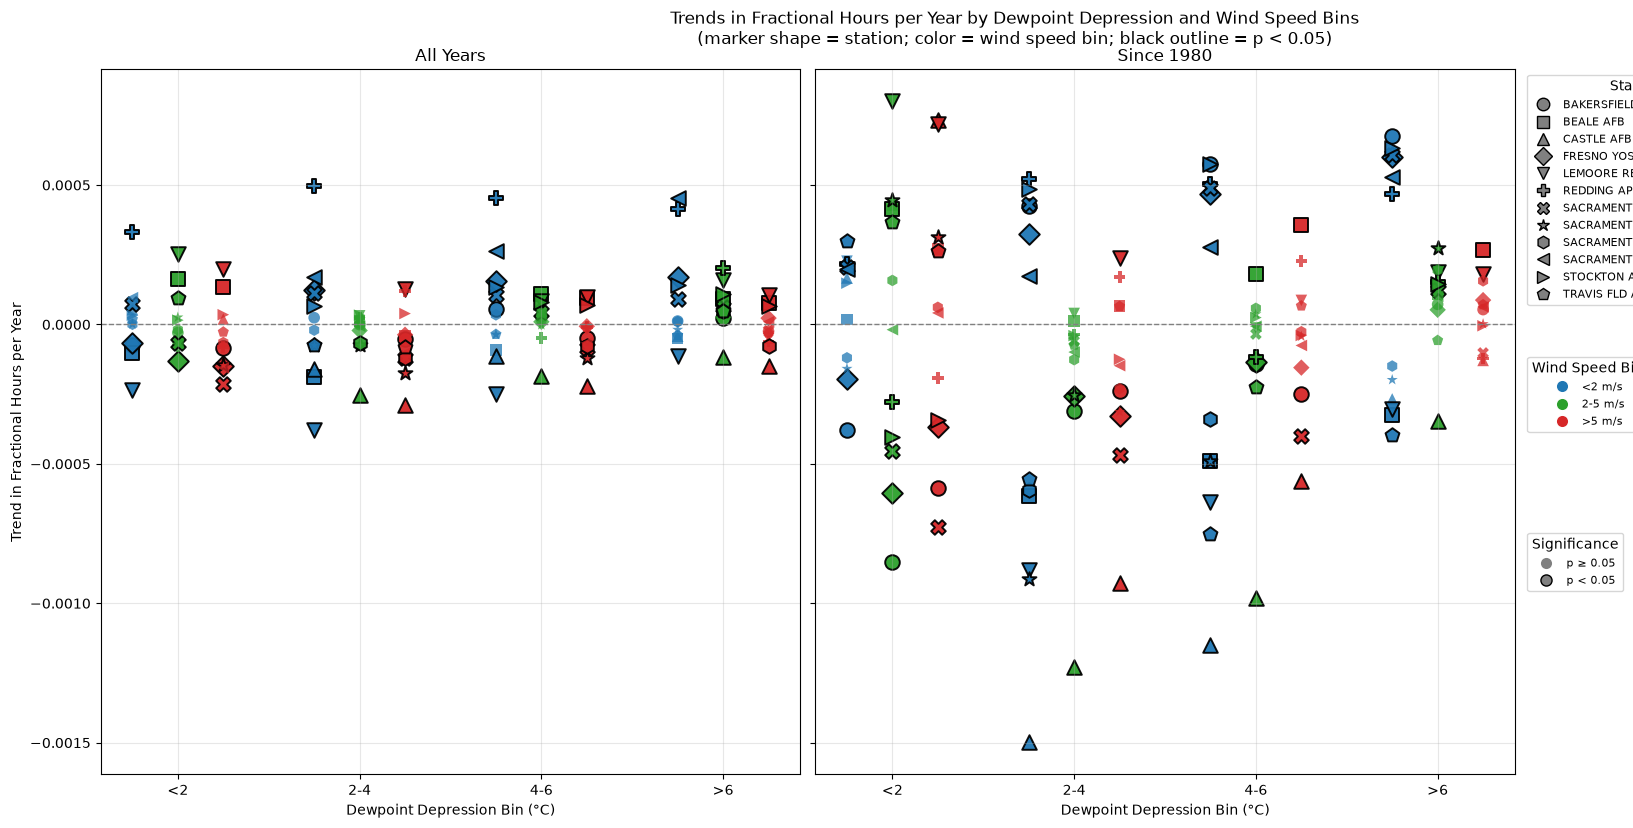

,period,STATION,dd_bin,wind_bin,slope_per_year,p_value,significant
0,All Years,BAKERSFIELD AP,<2,<2,-7.365387e-05,0.000155,True
1,All Years,BAKERSFIELD AP,<2,2-5,-2.953705e-05,0.195422,False
2,All Years,BAKERSFIELD AP,<2,>5,-8.436785e-05,0.000068,True
3,All Years,BAKERSFIELD AP,2-4,<2,2.420554e-05,0.089446,False
4,All Years,BAKERSFIELD AP,2-4,2-5,-6.165570e-07,0.959066,False
...,...,...,...,...,...,...,...
283,Since 1980,TRAVIS FLD AFB,4-6,2-5,-2.245644e-04,0.005207,True
284,Since 1980,TRAVIS FLD AFB,4-6,>5,6.665743e-05,0.286394,False
285,Since 1980,TRAVIS FLD AFB,>6,<2,-3.959079e-04,0.002761,True
286,Since 1980,TRAVIS FLD AFB,>6,2-5,-5.709139e-05,0.319036,False


In [13]:
# Trend in fractional unique days per year by dewpoint depression bin
# (<2, 2-4, 4-6, >6) and wind speed bin (<2, 2-5, >5 m/s), computed for
# all years and since 1980. Marker shape = station; color = wind bin;
# black outline = p < 0.05.
# Change this code to use hours instead of days
#Modify this plot so the legend is not cut off 
# Display what stations are which shapes separately
for station, marker in station_markers.items():
    print(f"Station {station} uses marker '{marker}'")

# New dewpoint depression bins
dd2_bin_edges = [-np.inf, 2.0, 4.0, 6.0, np.inf]
dd2_bin_labels = ["<2", "2-4", "4-6", ">6"]
dd2_positions = {label: i for i, label in enumerate(dd2_bin_labels)}

plot_data2 = CV_rows.loc[
    CV_rows["HourlyDewpointDepression"].notna()
    & CV_rows["HourlyWindSpeed"].notna(),
    ["STATION", "year", "month", "day", "hour", "HourlyDewpointDepression", "HourlyWindSpeed"],
].copy()

plot_data2["dd_bin"] = pd.cut(
    plot_data2["HourlyDewpointDepression"],
    bins=dd2_bin_edges, labels=dd2_bin_labels, right=False,
)
plot_data2["wind_bin"] = pd.cut(
    plot_data2["HourlyWindSpeed"],
    bins=wind_bin_edges, labels=wind_bin_labels, right=False, include_lowest=True,
)

periods = {"All Years": None, "Since 1980": 1980}

trend_records2 = []

for period_name, start_year in periods.items():
    period_data = plot_data2 if start_year is None else plot_data2[plot_data2["year"] >= start_year]

    for station in station_names:
        station_data = period_data[period_data["STATION"] == station]
        years = np.sort(station_data["year"].unique())

        if len(years) < 3:
            continue

        for dd_label in dd2_bin_labels:
            for wind_label in wind_bin_labels:
                subset = station_data[
                    (station_data["dd_bin"] == dd_label)
                    & (station_data["wind_bin"] == wind_label)
                ]

                annual_hours = (
                    subset[["year", "month", "day", "hour", "HourlyDewpointDepression"]]
                    .drop_duplicates()
                    .groupby("year")
                    .size()
                    .reindex(years, fill_value=0)
                )

                if annual_hours.sum() == 0:
                    continue

                y = (annual_hours / annual_hours.sum()).to_numpy()
                slope, intercept, r_value, p_value, std_err = stats.linregress(years, y)

                trend_records2.append({
                    "period": period_name,
                    "STATION": station,
                    "dd_bin": dd_label,
                    "wind_bin": wind_label,
                    "slope_per_year": slope,
                    "p_value": p_value,
                    "significant": bool(np.isfinite(p_value) and p_value < 0.05),
                })

trend_df2 = pd.DataFrame(trend_records2)

# Keep logical ordering for display
trend_df2["period"] = pd.Categorical(trend_df2["period"], categories=list(periods), ordered=True)
trend_df2["dd_bin"] = pd.Categorical(trend_df2["dd_bin"], categories=dd2_bin_labels, ordered=True)
trend_df2["wind_bin"] = pd.Categorical(trend_df2["wind_bin"], categories=wind_bin_labels, ordered=True)

# Plot: one panel per period
fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharey=True)

for ax, period_name in zip(axes, periods):
    period_trends = trend_df2[trend_df2["period"] == period_name]

    for station in station_names:
        sub = period_trends[period_trends["STATION"] == station]
        if sub.empty:
            continue

        marker = station_markers[station]

        for wind_label in wind_bin_labels:
            wind_sub = sub[sub["wind_bin"] == wind_label]
            if wind_sub.empty:
                continue

            x_vals = wind_sub["dd_bin"].map(dd2_positions).to_numpy() + wind_offsets[wind_label]

            ns = ~wind_sub["significant"]
            ax.scatter(
                x_vals[ns], wind_sub.loc[ns, "slope_per_year"],
                s=70, marker=marker, color=wind_colors[wind_label],
                alpha=0.75, edgecolors="none",
            )

            sg = wind_sub["significant"]
            ax.scatter(
                x_vals[sg], wind_sub.loc[sg, "slope_per_year"],
                s=110, marker=marker, color=wind_colors[wind_label],
                alpha=0.95, edgecolors="black", linewidths=1.4,
            )

    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_xticks(range(len(dd2_bin_labels)))
    ax.set_xticklabels(dd2_bin_labels)
    ax.set_xlabel("Dewpoint Depression Bin (°C)")
    ax.set_title(period_name)
    ax.grid(True, alpha=0.3)
fig.tight_layout()

axes[0].set_ylabel("Trend in Fractional Hours per Year")

fig.suptitle(
    "Trends in Fractional Hours per Year by Dewpoint Depression and Wind Speed Bins\n"
    "(marker shape = station; color = wind speed bin; black outline = p < 0.05)",
    y=1.03,
)

station_handles = [
    plt.Line2D([0], [0], marker=station_markers[st], color="w", label=st,
               markerfacecolor="gray", markeredgecolor="black", markersize=9)
    for st in station_names
]
legend1 = axes[1].legend(handles=station_handles, title="Station",
                         loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
axes[1].add_artist(legend1)

wind_handles = [
    plt.Line2D([0], [0], marker="o", color="w", label=f"{wl} m/s",
               markerfacecolor=wind_colors[wl], markersize=9)
    for wl in wind_bin_labels
]
legend2 = axes[1].legend(handles=wind_handles, title="Wind Speed Bin",
                         loc="upper left", bbox_to_anchor=(1.01, 0.6), fontsize=8)
axes[1].add_artist(legend2)

sig_handles = [
    plt.Line2D([0], [0], marker="o", color="w", label="p ≥ 0.05",
               markerfacecolor="gray", markeredgecolor="none", markersize=8),
    plt.Line2D([0], [0], marker="o", color="w", label="p < 0.05",
               markerfacecolor="gray", markeredgecolor="black", markersize=8),
]
axes[1].legend(handles=sig_handles, title="Significance",
               loc="upper left", bbox_to_anchor=(1.01, 0.35), fontsize=8)

plt.subplots_adjust(right=0.75)
plt.show()

display(trend_df2.sort_values(["period", "STATION", "dd_bin", "wind_bin"]))

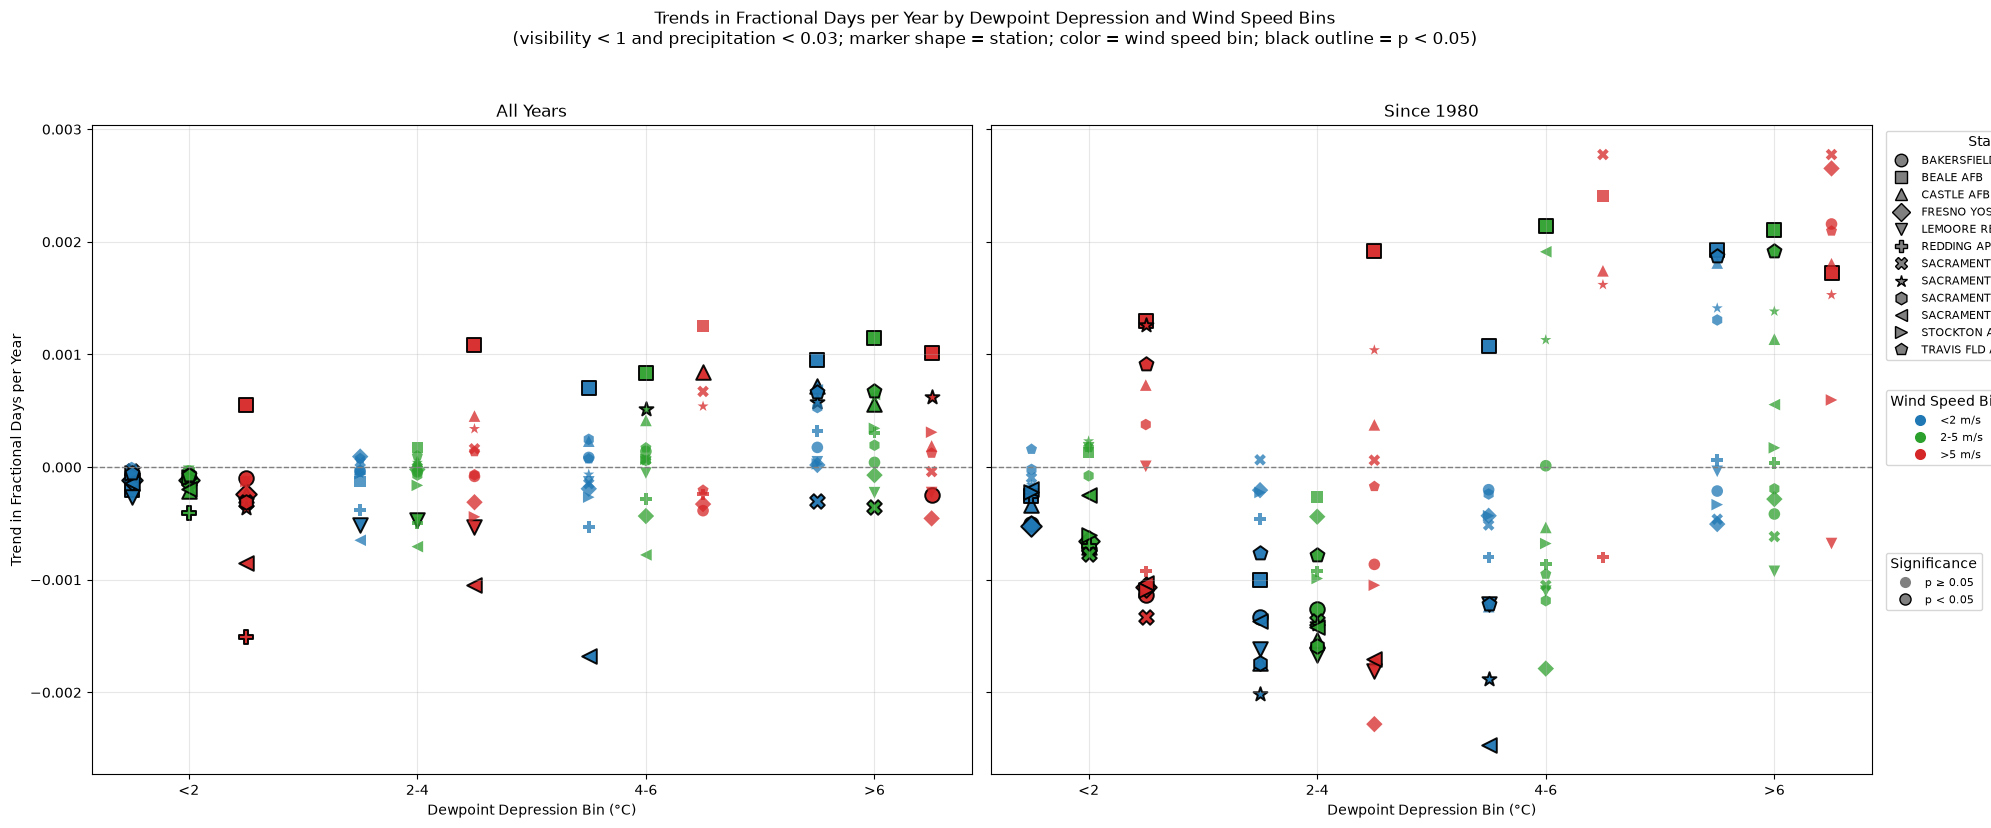

,period,STATION,dd_bin,wind_bin,slope_per_year,p_value,significant
0,All Years,BAKERSFIELD AP,<2,<2,-0.000060,0.000448,True
1,All Years,BAKERSFIELD AP,<2,2-5,-0.000035,0.095233,False
2,All Years,BAKERSFIELD AP,<2,>5,-0.000100,0.016621,True
3,All Years,BAKERSFIELD AP,2-4,<2,-0.000037,0.611697,False
4,All Years,BAKERSFIELD AP,2-4,2-5,-0.000042,0.504830,False
...,...,...,...,...,...,...,...
264,Since 1980,TRAVIS FLD AFB,4-6,<2,-0.001218,0.036563,True
265,Since 1980,TRAVIS FLD AFB,4-6,2-5,-0.000950,0.117902,False
266,Since 1980,TRAVIS FLD AFB,>6,<2,0.001871,0.038522,True
267,Since 1980,TRAVIS FLD AFB,>6,2-5,0.001920,0.007301,True


In [14]:
# Same as the plot above, but only using observations with
# HourlyVisibility < 1 and HourlyPrecipitation < 0.03

plot_data3 = CV_rows.loc[
    CV_rows["HourlyDewpointDepression"].notna()
    & CV_rows["HourlyWindSpeed"].notna()
    & (pd.to_numeric(CV_rows["HourlyVisibility"], errors="coerce") < 1)
    & (pd.to_numeric(CV_rows["HourlyPrecipitation"], errors="coerce") < 0.03),
    ["STATION", "year", "month", "day", "HourlyDewpointDepression", "HourlyWindSpeed"],
].copy()

plot_data3["dd_bin"] = pd.cut(
    plot_data3["HourlyDewpointDepression"],
    bins=dd2_bin_edges, labels=dd2_bin_labels, right=False,
)
plot_data3["wind_bin"] = pd.cut(
    plot_data3["HourlyWindSpeed"],
    bins=wind_bin_edges, labels=wind_bin_labels, right=False, include_lowest=True,
)

trend_records3 = []

for period_name, start_year in periods.items():
    period_data = plot_data3 if start_year is None else plot_data3[plot_data3["year"] >= start_year]

    for station in station_names:
        station_data = period_data[period_data["STATION"] == station]
        years = np.sort(station_data["year"].unique())

        if len(years) < 3:
            continue

        for dd_label in dd2_bin_labels:
            for wind_label in wind_bin_labels:
                subset = station_data[
                    (station_data["dd_bin"] == dd_label)
                    & (station_data["wind_bin"] == wind_label)
                ]

                annual_days = (
                    subset[["year", "month", "day"]]
                    .drop_duplicates()
                    .groupby("year")
                    .size()
                    .reindex(years, fill_value=0)
                )

                if annual_days.sum() == 0:
                    continue

                y = (annual_days / annual_days.sum()).to_numpy()
                slope, intercept, r_value, p_value, std_err = stats.linregress(years, y)

                trend_records3.append({
                    "period": period_name,
                    "STATION": station,
                    "dd_bin": dd_label,
                    "wind_bin": wind_label,
                    "slope_per_year": slope,
                    "p_value": p_value,
                    "significant": bool(np.isfinite(p_value) and p_value < 0.05),
                })

trend_df3 = pd.DataFrame(trend_records3)

# Keep logical ordering for display
trend_df3["period"] = pd.Categorical(trend_df3["period"], categories=list(periods), ordered=True)
trend_df3["dd_bin"] = pd.Categorical(trend_df3["dd_bin"], categories=dd2_bin_labels, ordered=True)
trend_df3["wind_bin"] = pd.Categorical(trend_df3["wind_bin"], categories=wind_bin_labels, ordered=True)

# Plot: one panel per period
fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharey=True)

for ax, period_name in zip(axes, periods):
    period_trends = trend_df3[trend_df3["period"] == period_name]

    for station in station_names:
        sub = period_trends[period_trends["STATION"] == station]
        if sub.empty:
            continue

        marker = station_markers[station]

        for wind_label in wind_bin_labels:
            wind_sub = sub[sub["wind_bin"] == wind_label]
            if wind_sub.empty:
                continue

            x_vals = wind_sub["dd_bin"].map(dd2_positions).to_numpy() + wind_offsets[wind_label]

            ns = ~wind_sub["significant"]
            ax.scatter(
                x_vals[ns], wind_sub.loc[ns, "slope_per_year"],
                s=70, marker=marker, color=wind_colors[wind_label],
                alpha=0.75, edgecolors="none",
            )

            sg = wind_sub["significant"]
            ax.scatter(
                x_vals[sg], wind_sub.loc[sg, "slope_per_year"],
                s=110, marker=marker, color=wind_colors[wind_label],
                alpha=0.95, edgecolors="black", linewidths=1.4,
            )

    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_xticks(range(len(dd2_bin_labels)))
    ax.set_xticklabels(dd2_bin_labels)
    ax.set_xlabel("Dewpoint Depression Bin (°C)")
    ax.set_title(period_name)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Trend in Fractional Days per Year")

fig.suptitle(
    "Trends in Fractional Days per Year by Dewpoint Depression and Wind Speed Bins\n"
    "(visibility < 1 and precipitation < 0.03; marker shape = station; color = wind speed bin; black outline = p < 0.05)",
    y=1.03,
)

station_handles = [
    plt.Line2D([0], [0], marker=station_markers[st], color="w", label=st,
               markerfacecolor="gray", markeredgecolor="black", markersize=9)
    for st in station_names
]
legend1 = axes[1].legend(handles=station_handles, title="Station",
                         loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
axes[1].add_artist(legend1)

wind_handles = [
    plt.Line2D([0], [0], marker="o", color="w", label=f"{wl} m/s",
               markerfacecolor=wind_colors[wl], markersize=9)
    for wl in wind_bin_labels
]
legend2 = axes[1].legend(handles=wind_handles, title="Wind Speed Bin",
                         loc="upper left", bbox_to_anchor=(1.01, 0.6), fontsize=8)
axes[1].add_artist(legend2)

sig_handles = [
    plt.Line2D([0], [0], marker="o", color="w", label="p ≥ 0.05",
               markerfacecolor="gray", markeredgecolor="none", markersize=8),
    plt.Line2D([0], [0], marker="o", color="w", label="p < 0.05",
               markerfacecolor="gray", markeredgecolor="black", markersize=8),
]
axes[1].legend(handles=sig_handles, title="Significance",
               loc="upper left", bbox_to_anchor=(1.01, 0.35), fontsize=8)

plt.tight_layout()
plt.show()

display(trend_df3.sort_values(["period", "STATION", "dd_bin", "wind_bin"]))

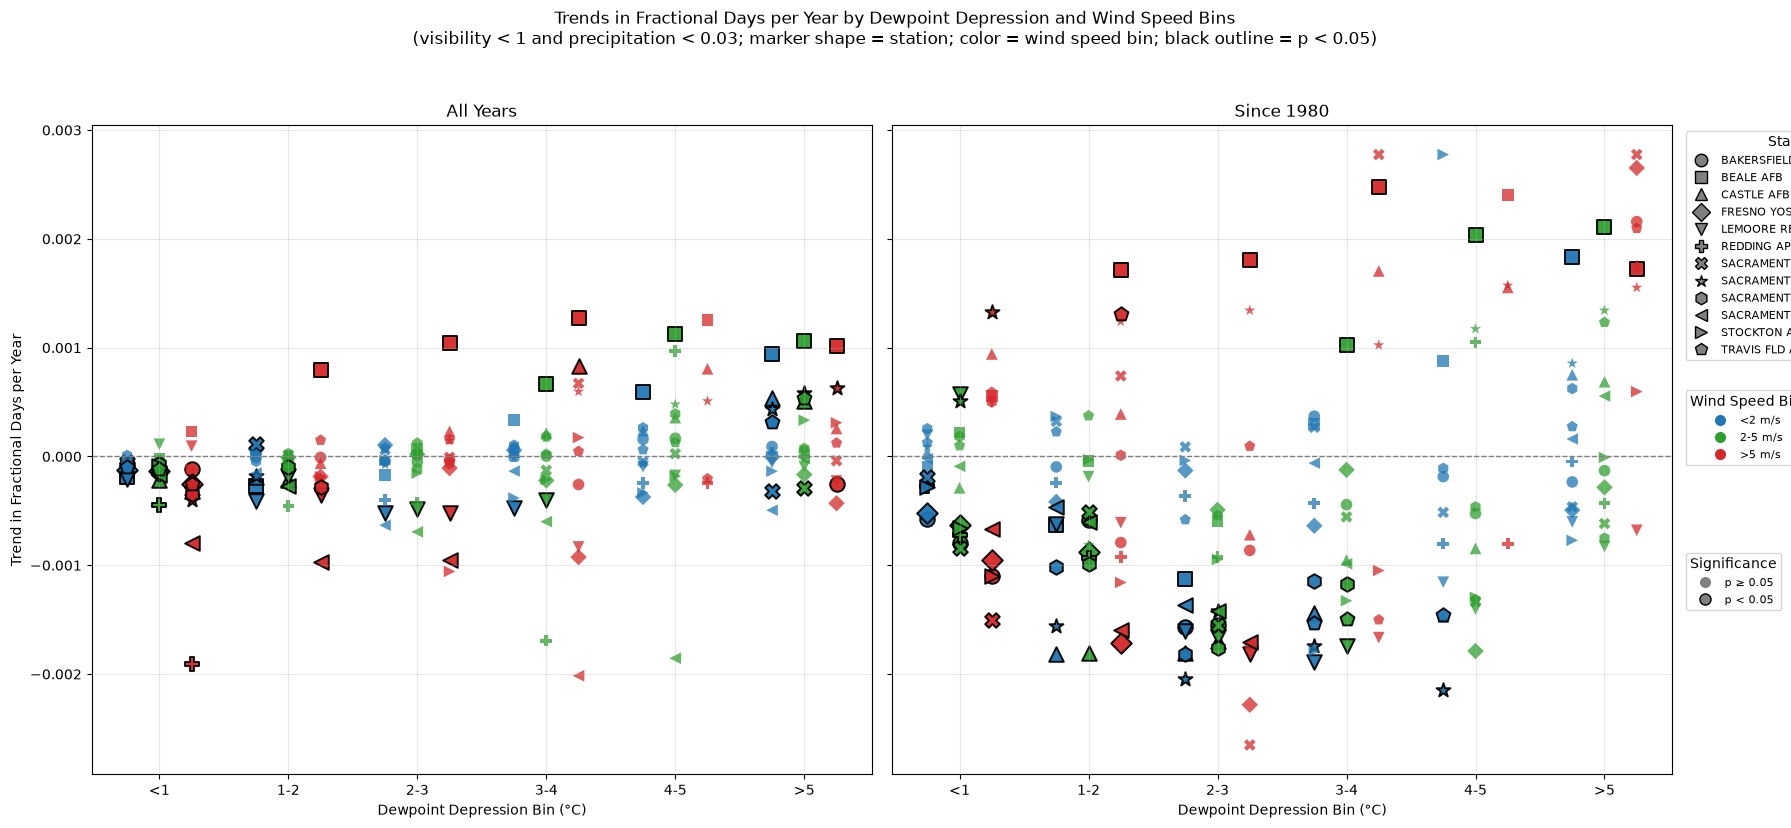

,period,STATION,dd_bin,wind_bin,slope_per_year,p_value,significant
0,All Years,BAKERSFIELD AP,<1,<2,-0.000072,0.000280,True
1,All Years,BAKERSFIELD AP,<1,2-5,-0.000039,0.094902,False
2,All Years,BAKERSFIELD AP,<1,>5,-0.000114,0.013957,True
3,All Years,BAKERSFIELD AP,1-2,<2,-0.000009,0.805245,False
4,All Years,BAKERSFIELD AP,1-2,2-5,-0.000007,0.880691,False
...,...,...,...,...,...,...,...
390,Since 1980,TRAVIS FLD AFB,4-5,<2,-0.001457,0.021359,True
391,Since 1980,TRAVIS FLD AFB,4-5,2-5,-0.001316,0.054833,False
392,Since 1980,TRAVIS FLD AFB,>5,<2,0.000275,0.632817,False
393,Since 1980,TRAVIS FLD AFB,>5,2-5,0.001233,0.051903,False


In [15]:
# Same plot as above, but with dewpoint depression bins in 1°C increments:
# <1, 1-2, 2-3, 3-4, 4-5, >5 (visibility < 1 and precipitation < 0.03)


dd3_bin_edges = [-np.inf, 1.0, 2.0, 3.0, 4.0, 5.0, np.inf]
dd3_bin_labels = ["<1", "1-2", "2-3", "3-4", "4-5", ">5"]
dd3_positions = {label: i for i, label in enumerate(dd3_bin_labels)}

plot_data4 = CV_rows.loc[
    CV_rows["HourlyDewpointDepression"].notna()
    & CV_rows["HourlyWindSpeed"].notna()
    & (pd.to_numeric(CV_rows["HourlyVisibility"], errors="coerce") < 1)
    & (pd.to_numeric(CV_rows["HourlyPrecipitation"], errors="coerce") < 0.03),
    ["STATION", "year", "month", "day", "HourlyDewpointDepression", "HourlyWindSpeed"],
].copy()

plot_data4["dd_bin"] = pd.cut(
    plot_data4["HourlyDewpointDepression"],
    bins=dd3_bin_edges, labels=dd3_bin_labels, right=False,
)
plot_data4["wind_bin"] = pd.cut(
    plot_data4["HourlyWindSpeed"],
    bins=wind_bin_edges, labels=wind_bin_labels, right=False, include_lowest=True,
)

trend_records4 = []

for period_name, start_year in periods.items():
    period_data = plot_data4 if start_year is None else plot_data4[plot_data4["year"] >= start_year]

    for station in station_names:
        station_data = period_data[period_data["STATION"] == station]
        years = np.sort(station_data["year"].unique())

        if len(years) < 3:
            continue

        for dd_label in dd3_bin_labels:
            for wind_label in wind_bin_labels:
                subset = station_data[
                    (station_data["dd_bin"] == dd_label)
                    & (station_data["wind_bin"] == wind_label)
                ]

                annual_days = (
                    subset[["year", "month", "day"]]
                    .drop_duplicates()
                    .groupby("year")
                    .size()
                    .reindex(years, fill_value=0)
                )

                if annual_days.sum() == 0:
                    continue

                y = (annual_days / annual_days.sum()).to_numpy()
                slope, intercept, r_value, p_value, std_err = stats.linregress(years, y)

                trend_records4.append({
                    "period": period_name,
                    "STATION": station,
                    "dd_bin": dd_label,
                    "wind_bin": wind_label,
                    "slope_per_year": slope,
                    "p_value": p_value,
                    "significant": bool(np.isfinite(p_value) and p_value < 0.05),
                })

trend_df4 = pd.DataFrame(trend_records4)

# Keep logical ordering for display
trend_df4["period"] = pd.Categorical(trend_df4["period"], categories=list(periods), ordered=True)
trend_df4["dd_bin"] = pd.Categorical(trend_df4["dd_bin"], categories=dd3_bin_labels, ordered=True)
trend_df4["wind_bin"] = pd.Categorical(trend_df4["wind_bin"], categories=wind_bin_labels, ordered=True)

# Plot: one panel per period
fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharey=True)

for ax, period_name in zip(axes, periods):
    period_trends = trend_df4[trend_df4["period"] == period_name]

    for station in station_names:
        sub = period_trends[period_trends["STATION"] == station]
        if sub.empty:
            continue

        marker = station_markers[station]

        for wind_label in wind_bin_labels:
            wind_sub = sub[sub["wind_bin"] == wind_label]
            if wind_sub.empty:
                continue

            x_vals = wind_sub["dd_bin"].map(dd3_positions).to_numpy() + wind_offsets[wind_label]

            ns = ~wind_sub["significant"]
            ax.scatter(
                x_vals[ns], wind_sub.loc[ns, "slope_per_year"],
                s=70, marker=marker, color=wind_colors[wind_label],
                alpha=0.75, edgecolors="none",
            )

            sg = wind_sub["significant"]
            ax.scatter(
                x_vals[sg], wind_sub.loc[sg, "slope_per_year"],
                s=110, marker=marker, color=wind_colors[wind_label],
                alpha=0.95, edgecolors="black", linewidths=1.4,
            )

    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_xticks(range(len(dd3_bin_labels)))
    ax.set_xticklabels(dd3_bin_labels)
    ax.set_xlabel("Dewpoint Depression Bin (°C)")
    ax.set_title(period_name)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Trend in Fractional Days per Year")

fig.suptitle(
    "Trends in Fractional Days per Year by Dewpoint Depression and Wind Speed Bins\n"
    "(visibility < 1 and precipitation < 0.03; marker shape = station; color = wind speed bin; black outline = p < 0.05)",
    y=1.03,
)

station_handles = [
    plt.Line2D([0], [0], marker=station_markers[st], color="w", label=st,
               markerfacecolor="gray", markeredgecolor="black", markersize=9)
    for st in station_names
]
legend1 = axes[1].legend(handles=station_handles, title="Station",
                         loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
axes[1].add_artist(legend1)

wind_handles = [
    plt.Line2D([0], [0], marker="o", color="w", label=f"{wl} m/s",
               markerfacecolor=wind_colors[wl], markersize=9)
    for wl in wind_bin_labels
]
legend2 = axes[1].legend(handles=wind_handles, title="Wind Speed Bin",
                         loc="upper left", bbox_to_anchor=(1.01, 0.6), fontsize=8)
axes[1].add_artist(legend2)

sig_handles = [
    plt.Line2D([0], [0], marker="o", color="w", label="p ≥ 0.05",
               markerfacecolor="gray", markeredgecolor="none", markersize=8),
    plt.Line2D([0], [0], marker="o", color="w", label="p < 0.05",
               markerfacecolor="gray", markeredgecolor="black", markersize=8),
]
axes[1].legend(handles=sig_handles, title="Significance",
               loc="upper left", bbox_to_anchor=(1.01, 0.35), fontsize=8)

plt.tight_layout()
plt.show()

display(trend_df4.sort_values(["period", "STATION", "dd_bin", "wind_bin"]))

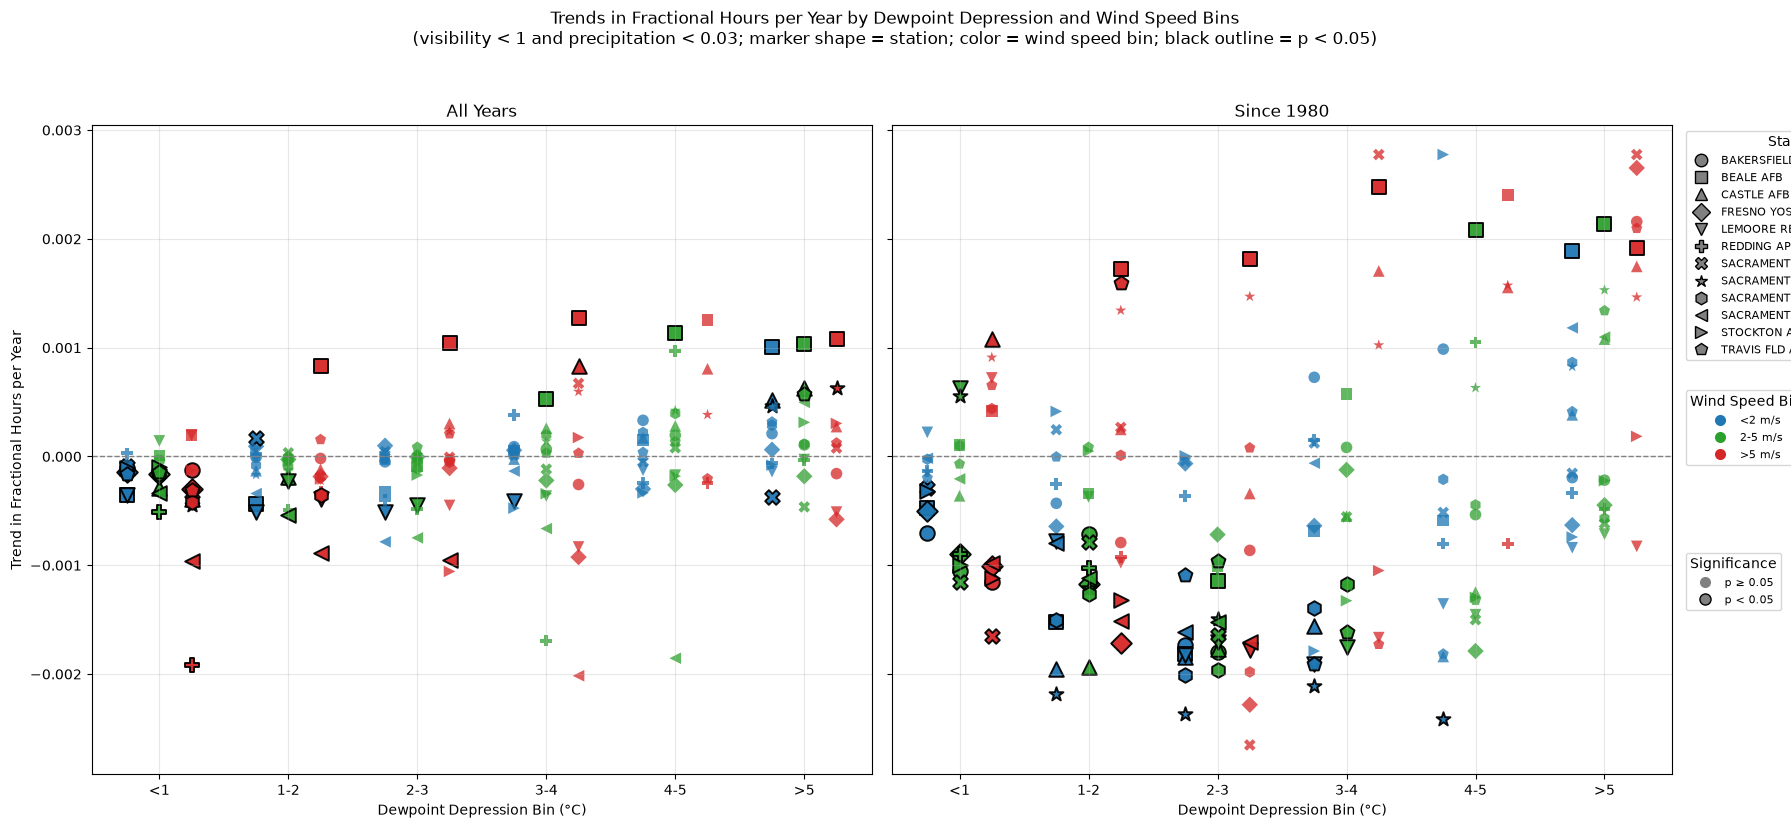

,period,STATION,dd_bin,wind_bin,slope_per_year,p_value,significant
0,All Years,BAKERSFIELD AP,<1,<2,-0.000102,0.000448,True
1,All Years,BAKERSFIELD AP,<1,2-5,-0.000036,0.317623,False
2,All Years,BAKERSFIELD AP,<1,>5,-0.000126,0.011359,True
3,All Years,BAKERSFIELD AP,1-2,<2,-0.000008,0.877411,False
4,All Years,BAKERSFIELD AP,1-2,2-5,-0.000027,0.681912,False
...,...,...,...,...,...,...,...
390,Since 1980,TRAVIS FLD AFB,4-5,<2,-0.001815,0.053184,False
391,Since 1980,TRAVIS FLD AFB,4-5,2-5,-0.001321,0.075969,False
392,Since 1980,TRAVIS FLD AFB,>5,<2,0.000413,0.542212,False
393,Since 1980,TRAVIS FLD AFB,>5,2-5,0.001340,0.113612,False


In [16]:
# Same plot as above, but with dewpoint depression bins in 1°C increments:
# <1, 1-2, 2-3, 3-4, 4-5, >5 (visibility < 1 and precipitation < 0.03)
# use hours (counts) per year instead of days per year


dd3_bin_edges = [-np.inf, 1.0, 2.0, 3.0, 4.0, 5.0, np.inf]
dd3_bin_labels = ["<1", "1-2", "2-3", "3-4", "4-5", ">5"]
dd3_positions = {label: i for i, label in enumerate(dd3_bin_labels)}

plot_data4 = CV_rows.loc[
    CV_rows["HourlyDewpointDepression"].notna()
    & CV_rows["HourlyWindSpeed"].notna()
    & (pd.to_numeric(CV_rows["HourlyVisibility"], errors="coerce") < 1)
    & (pd.to_numeric(CV_rows["HourlyPrecipitation"], errors="coerce") < 0.03),
    ["STATION", "year", "month", "day", "hour", "HourlyDewpointDepression", "HourlyWindSpeed"],
].copy()

plot_data4["dd_bin"] = pd.cut(
    plot_data4["HourlyDewpointDepression"],
    bins=dd3_bin_edges, labels=dd3_bin_labels, right=False,
)
plot_data4["wind_bin"] = pd.cut(
    plot_data4["HourlyWindSpeed"],
    bins=wind_bin_edges, labels=wind_bin_labels, right=False, include_lowest=True,
)

trend_records4 = []

for period_name, start_year in periods.items():
    period_data = plot_data4 if start_year is None else plot_data4[plot_data4["year"] >= start_year]

    for station in station_names:
        station_data = period_data[period_data["STATION"] == station]
        years = np.sort(station_data["year"].unique())

        if len(years) < 3:
            continue

        for dd_label in dd3_bin_labels:
            for wind_label in wind_bin_labels:
                subset = station_data[
                    (station_data["dd_bin"] == dd_label)
                    & (station_data["wind_bin"] == wind_label)
                ]

                annual_hours = (
                    subset[["year", "month", "day", "hour", "HourlyDewpointDepression"]]
                    .drop_duplicates()
                    .groupby("year")
                    .size() * 24
                )
                annual_hours = annual_hours.reindex(years, fill_value=0)

                if annual_hours.sum() == 0:
                    continue

                y = (annual_hours / annual_hours.sum()).to_numpy()

                slope, intercept, r_value, p_value, std_err = stats.linregress(years, y)

                trend_records4.append({
                    "period": period_name,
                    "STATION": station,
                    "dd_bin": dd_label,
                    "wind_bin": wind_label,
                    "slope_per_year": slope,
                    "p_value": p_value,
                    "significant": bool(np.isfinite(p_value) and p_value < 0.05),
                })

trend_df4 = pd.DataFrame(trend_records4)

# Keep logical ordering for display
trend_df4["period"] = pd.Categorical(trend_df4["period"], categories=list(periods), ordered=True)
trend_df4["dd_bin"] = pd.Categorical(trend_df4["dd_bin"], categories=dd3_bin_labels, ordered=True)
trend_df4["wind_bin"] = pd.Categorical(trend_df4["wind_bin"], categories=wind_bin_labels, ordered=True)

# Plot: one panel per period
fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharey=True)

for ax, period_name in zip(axes, periods):
    period_trends = trend_df4[trend_df4["period"] == period_name]

    for station in station_names:
        sub = period_trends[period_trends["STATION"] == station]
        if sub.empty:
            continue

        marker = station_markers[station]

        for wind_label in wind_bin_labels:
            wind_sub = sub[sub["wind_bin"] == wind_label]
            if wind_sub.empty:
                continue

            x_vals = wind_sub["dd_bin"].map(dd3_positions).to_numpy() + wind_offsets[wind_label]

            ns = ~wind_sub["significant"]
            ax.scatter(
                x_vals[ns], wind_sub.loc[ns, "slope_per_year"],
                s=70, marker=marker, color=wind_colors[wind_label],
                alpha=0.75, edgecolors="none",
            )

            sg = wind_sub["significant"]
            ax.scatter(
                x_vals[sg], wind_sub.loc[sg, "slope_per_year"],
                s=110, marker=marker, color=wind_colors[wind_label],
                alpha=0.95, edgecolors="black", linewidths=1.4,
            )

    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_xticks(range(len(dd3_bin_labels)))
    ax.set_xticklabels(dd3_bin_labels)
    ax.set_xlabel("Dewpoint Depression Bin (°C)")
    ax.set_title(period_name)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Trend in Fractional Hours per Year")

fig.suptitle(
    "Trends in Fractional Hours per Year by Dewpoint Depression and Wind Speed Bins\n"
    "(visibility < 1 and precipitation < 0.03; marker shape = station; color = wind speed bin; black outline = p < 0.05)",
    y=1.03,
)

station_handles = [
    plt.Line2D([0], [0], marker=station_markers[st], color="w", label=st,
               markerfacecolor="gray", markeredgecolor="black", markersize=9)
    for st in station_names
]
legend1 = axes[1].legend(handles=station_handles, title="Station",
                         loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
axes[1].add_artist(legend1)

wind_handles = [
    plt.Line2D([0], [0], marker="o", color="w", label=f"{wl} m/s",
               markerfacecolor=wind_colors[wl], markersize=9)
    for wl in wind_bin_labels
]
legend2 = axes[1].legend(handles=wind_handles, title="Wind Speed Bin",
                         loc="upper left", bbox_to_anchor=(1.01, 0.6), fontsize=8)
axes[1].add_artist(legend2)

sig_handles = [
    plt.Line2D([0], [0], marker="o", color="w", label="p ≥ 0.05",
               markerfacecolor="gray", markeredgecolor="none", markersize=8),
    plt.Line2D([0], [0], marker="o", color="w", label="p < 0.05",
               markerfacecolor="gray", markeredgecolor="black", markersize=8),
]
axes[1].legend(handles=sig_handles, title="Significance",
               loc="upper left", bbox_to_anchor=(1.01, 0.35), fontsize=8)

plt.tight_layout()
plt.show()

display(trend_df4.sort_values(["period", "STATION", "dd_bin", "wind_bin"]))